# 02. Tools and MCP

## Problem

A malformed search must fail before retrieval, while a backend timeout must remain distinct from a successful empty result. The same search is also exposed through MCP.

## Learning objectives

Design tool schemas, preserve call IDs, classify errors, bound reads and pagination, execute local MCP, and configure authenticated remote transport.

Run top to bottom in a fresh kernel. The default path uses temporary storage and scripted inference with actual framework orchestration. Every plotted value is labelled measured, estimated or illustrative.

In [1]:
import os
from pathlib import Path
from tempfile import TemporaryDirectory
from IPython.display import display
ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents]
            if (path / "pyproject.toml").exists())
scratch = TemporaryDirectory(prefix="northstar-course-")
os.environ["MPLCONFIGDIR"] = str(Path(scratch.name) / "matplotlib")
os.environ["LANGSMITH_TRACING"] = "false"
os.environ["LANGCHAIN_TRACING_V2"] = "false"
import matplotlib
get_ipython().run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt
from deep_agent_lab.settings import Settings
from deep_agent_lab.courseware import diagram, bars
settings = Settings(_env_file=None, deep_lab_mode="demo", langfuse_enabled=False,
                    deep_lab_state_dir=Path(scratch.name) / "state")
assert settings.deep_lab_mode == "demo" and not settings.langfuse_enabled

## Concept explanation

## Tool descriptions influence behavior

A poorly designed tool might look like this:

The model cannot reliably infer what source it searches, how many results are returned, or what a failure looks like.

A better design uses explicit arguments and an unambiguous description:

Now the model sees exactly which search modes are valid.

The application can reject invalid requests before consuming backend resources.

## Three outcomes that must remain distinct

**Successful search with zero matches**

The search ran correctly, but no evidence was found. The agent may reformulate its query or report an evidence gap.

**Invalid request**

The model supplied `top_k=100000`, which violates the contract. Reject it without executing retrieval.

**Transient infrastructure failure**

OpenSearch timed out. The absence of results has not been established. Retry within a budget or report retrieval unavailable.

Treating a timeout as "no results" creates a dangerous failure: the agent may confidently claim that a policy does not exist when the search backend was unavailable.

## MCP: Model Context Protocol

MCP standardizes communication between an application and external services exposing tools, resources, or prompts.

It separates three concepts:

- **Host:** The application running the assistant.
- **Client:** The protocol component connecting to a server.
- **Server:** The component exposing capabilities.

The repository's MCP lab already demonstrates a local `FastMCP` server over stdio.

For local development, stdio is often sufficient.

For independently hosted services, an HTTP transport may be appropriate, but it introduces authentication, authorization, server identity, networking, and protocol-version concerns.

**Important:** MCP is a protocol, not a security boundary by itself.

Tool outputs remain untrusted data. A remote server's description cannot authorize actions, and a retrieved document cannot grant itself permission to invoke a write.

## Mental model

Read the following diagram as an application boundary: the model proposes actions while the runtime performs validated operations. The figure renders through Matplotlib in the notebook output.

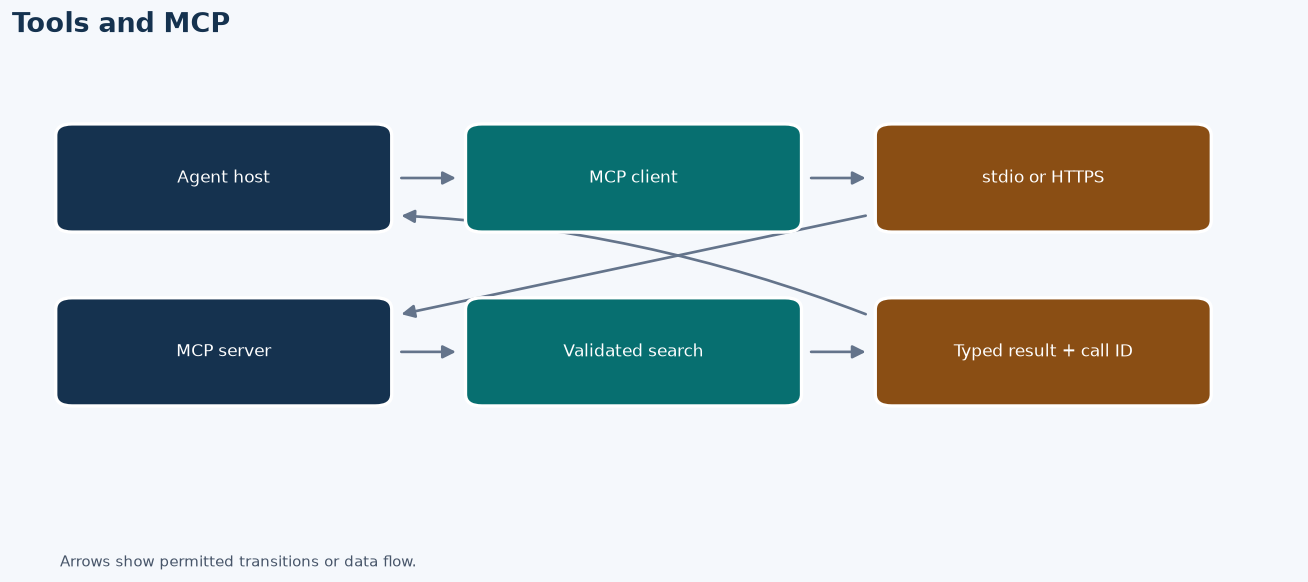

In [2]:
display(diagram('Tools and MCP', ['Agent host', 'MCP client', 'stdio or HTTPS', 'MCP server', 'Validated search', 'Typed result + call ID'], [(0, 1), (1, 2), (2, 3), (3, 4), (4, 5), (5, 0)]))
plt.close('all')

## Implementation from scratch

Build the smallest inspectable mechanism before connecting it to the full application. The code below exposes state and checks the invariant that motivates this module.

In [3]:
import asyncio
from typing import Literal
from pydantic import BaseModel,Field,ValidationError,ConfigDict
class SearchContract(BaseModel):
    model_config = ConfigDict(extra="forbid",strict=True)
    query: str = Field(min_length=1,max_length=4000)
    top_k: int = Field(default=3,ge=1,le=5)
    mode: Literal["keyword","semantic","hybrid"] = "hybrid"

async def small_read(operation,payload,attempts=2):
    if not 1 <= attempts <= 3:
        raise ValueError("Invalid attempt budget")
    request = SearchContract.model_validate(payload)
    for attempt in range(1,attempts+1):
        try:
            rows = await asyncio.wait_for(operation(request),timeout=0.01)
            return {"status":"success","hits":rows[:request.top_k],"attempts":attempt}
        except TimeoutError:
            if attempt == attempts:
                return {"status":"transient_error","hits":[],"attempts":attempt}

local_attempts = []
async def once_unavailable(request):
    local_attempts.append(request.query)
    if len(local_attempts) == 1:
        raise TimeoutError("fixture timeout")
    return [{"id":"restore"}]
manual = await small_read(once_unavailable,{"query":"restore","top_k":1})
assert manual["status"] == "success" and manual["attempts"] == 2
try:
    await small_read(once_unavailable,{"query":"restore","top_k":999})
except ValidationError:
    assert len(local_attempts) == 2
else:
    raise AssertionError("Invalid arguments reached the operation")
print("Model-facing schema:",SearchContract.model_json_schema())

import asyncio
from deep_agent_lab.tooling import search_read, collect_pages, remote_headers
calls = []
async def flaky_backend(request):
    calls.append(request.query)
    if len(calls) == 1:
        raise TimeoutError("synthetic transport outage")
    return [{"id": "restore", "excerpt": "policy " * 100}]

# This coroutine is the retry policy: only a read can enter this wrapper.
outcome = await search_read(flaky_backend, {"query": "restore", "top_k": 1},
                            call_id="tool-42", attempts=2, backoff=0)
assert outcome.status == "success" and outcome.attempts == 2
assert outcome.call_id == "tool-42" and len(outcome.hits[0]["excerpt"]) == 500
invalid = await search_read(flaky_backend, {"query": "restore", "top_k": 999}, call_id="invalid")
assert invalid.status == "invalid_request" and len(calls) == 2
print(outcome.model_dump())

Model-facing schema: {'additionalProperties': False, 'properties': {'query': {'maxLength': 4000, 'minLength': 1, 'title': 'Query', 'type': 'string'}, 'top_k': {'default': 3, 'maximum': 5, 'minimum': 1, 'title': 'Top K', 'type': 'integer'}, 'mode': {'default': 'hybrid', 'enum': ['keyword', 'semantic', 'hybrid'], 'title': 'Mode', 'type': 'string'}}, 'required': ['query'], 'title': 'SearchContract', 'type': 'object'}
{'call_id': 'tool-42', 'status': 'success', 'hits': [{'id': 'restore', 'excerpt': 'policy policy policy policy policy policy policy policy policy policy policy policy policy policy policy policy policy policy policy policy policy policy policy policy policy policy policy policy policy policy policy policy policy policy policy policy policy policy policy policy policy policy policy policy policy policy policy policy policy policy policy policy policy policy policy policy policy policy policy policy policy policy policy policy policy policy policy policy policy policy policy po

## Framework implementation

The following cell executes the existing Deep Agents/LangGraph application or its actual integration boundary. Any fixture ports or scripted responses are identified in the cell.

In [4]:
from deep_agent_lab.labs import mcp_lab
exchange = await mcp_lab()  # Starts a real FastMCP child and initializes ClientSession.
assert "search" in exchange["tools"] and "northstar-restore" in exchange["results"][0]
print(exchange["tools"])
from deep_agent_lab.mcp_server import search
print(search.__annotations__)

['search']


{'query': typing.Annotated[str, StringConstraints(strip_whitespace=True, to_upper=None, to_lower=None, strict=None, min_length=1, max_length=4000, pattern=None, ascii_only=None)], 'mode': typing.Literal['keyword', 'semantic', 'hybrid'], 'top_k': typing.Annotated[int, FieldInfo(annotation=NoneType, required=True, metadata=[Ge(ge=1), Le(le=5)])], 'return': list[dict]}


## Code walkthrough

`asyncio.timeout` bounds an async transport attempt; it cannot forcibly kill arbitrary blocking code. Cancellation propagates rather than becoming a retry. `ToolOutcome` keeps success-with-zero-hits distinct from unavailable retrieval. The MCP lab launches the repository's actual stdio server, discovers its schema, and calls it through ClientSession. Protocol request IDs and the agent's tool-call IDs serve different layers. `remote_mcp_search` uses the installed SDK's real Streamable HTTP client with redirects disabled; OAuth token acquisition belongs to the trusted identity layer. Tool descriptions and returned content grant no permissions.

## Interactive experiments

Vary attempt count, excerpt size and pagination budget. Treat a repeated cursor as a protocol failure rather than looping forever.

In [5]:
pages = {None: (["restore"], "next"), "next": (["incident"], None)}
async def fetch(cursor):
    return pages[cursor]
assert await collect_pages(fetch) == ["restore", "incident"]
headers = remote_headers("https://mcp.example/mcp", "fixture-token",
                         frozenset({"https://mcp.example"}))
assert headers["Authorization"].startswith("Bearer ")
print("Pagination completed; token is restricted to the exact HTTPS origin.")

# A real remote server is optional. The test suite exercises this SDK transport
# against an authenticated in-process FastMCP ASGI server without external traffic.
RUN_REMOTE_MCP = False
if RUN_REMOTE_MCP:
    from deep_agent_lab.tooling import remote_mcp_search
    endpoint = os.environ["NORTHSTAR_MCP_URL"]
    token = os.environ["NORTHSTAR_MCP_TOKEN"]
    trusted_origin = os.environ["NORTHSTAR_MCP_TRUSTED_ORIGIN"]
    remote = await remote_mcp_search(endpoint, token, frozenset({trusted_origin}), "production restore")
    assert not remote.isError

Pagination completed; token is restricted to the exact HTTPS origin.


## Failure experiment

Deliberately violate a contract or remove a required condition. A caught, asserted failure is an expected result; an uncaught error means this notebook has not passed.

In [6]:
async def slow(request):
    await asyncio.sleep(1)
    return []
failed = await search_read(slow, {"query": "restore"}, call_id="timeout", timeout=0.001, attempts=1)
empty = await search_read(lambda req: asyncio.sleep(0, result=[]), {"query": "missing"}, call_id="empty")
assert failed.status == "transient_error" and empty.status == "success"
assert failed.hits == empty.hits == []
try:
    remote_headers("https://mcp.example.evil/mcp", "fixture-token", frozenset({"https://mcp.example"}))
except PermissionError:
    print("Expected: credential forwarding to a lookalike origin was denied.")
else:
    raise AssertionError("Origin check failed")

Expected: credential forwarding to a lookalike origin was denied.


## Verification

These assertions inspect actual state produced above. They establish the stated contracts within this lab's scope.

In [7]:
assert invalid.attempts == 0 and outcome.attempts == 2
assert failed.error_code == "unavailable" and empty.error_code is None
print("Verified schema rejection, retry bounds, timeout classification and real stdio MCP.")

Verified schema rejection, retry bounds, timeout classification and real stdio MCP.


## Exercise

Collect a two-page MCP tool listing while allowing no more than two pages. Then simulate a server returning the same cursor forever and reject it.

Try your implementation before running the complete reference solution in the next cell.

### Reference solution

Compare the implementation and assertions with your attempt.

In [8]:
assert await collect_pages(fetch, max_pages=2) == ["restore", "incident"]
async def broken(cursor):
    return [], "same-cursor"
try:
    await collect_pages(broken, max_pages=3)
except ValueError as error:
    assert "cursor" in str(error)
else:
    raise AssertionError("Repeated cursor accepted")

## Trade-offs and further reading

MCP helps interoperability and process separation. A normal Python function is simpler for an internal tool in the same process. HTTP authentication must validate issuer, audience, expiry and scopes at the server; a bearer header helper does not implement an OAuth server. Remote MCP is optional and requires your own endpoint.

[Primary source 1](https://modelcontextprotocol.io/specification/2025-11-25/basic/transports) · [Primary source 2](https://modelcontextprotocol.io/specification/2025-11-25/basic/authorization)

In [9]:
plt.close('all')
scratch.cleanup()
print('All offline module assertions passed.')

All offline module assertions passed.
